# Decision Tree: Induction, Testing, and Visualization
**Name:** Eveline Audreylia Nauoliem

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import train_test_split, LeaveOneOut, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

---
## 1. Vertebrate Dataset (Table 4.1)
This dataset contains 15 animals, 7 attributes, and 5 classes: mammal, reptile, fish, amphibian, and bird.

In [12]:
vertebrate = pd.DataFrame({
    "Name": ["human", "python", "salmon", "whale", "frog", "komodo dragon", "bat", "pigeon",
             "cat", "leopard shark", "turtle", "penguin", "porcupine", "eel", "salamander"],
    "Body Temperature": ["warm-blooded", "cold-blooded", "cold-blooded", "warm-blooded", "cold-blooded",
                         "cold-blooded", "warm-blooded", "warm-blooded", "warm-blooded", "cold-blooded",
                         "cold-blooded", "warm-blooded", "warm-blooded", "cold-blooded", "cold-blooded"],
    "Skin Cover": ["hair", "scales", "scales", "hair", "none", "scales", "hair", "feathers",
                   "fur", "scales", "scales", "feathers", "quills", "scales", "none"],
    "Gives Birth": ["yes", "no", "no", "yes", "no", "no", "yes", "no", "yes", "yes", "no", "no", "yes", "no", "no"],
    "Aquatic Creature": ["no", "no", "yes", "yes", "semi", "no", "no", "no", "no", "yes", "semi", "semi", "no", "yes", "semi"],
    "Aerial Creature": ["no", "no", "no", "no", "no", "no", "yes", "yes", "no", "no", "no", "no", "no", "no", "no"],
    "Has Legs": ["yes", "no", "no", "no", "yes", "yes", "yes", "yes", "yes", "no", "yes", "yes", "yes", "no", "yes"],
    "Hibernates": ["no", "yes", "no", "no", "yes", "no", "yes", "no", "no", "no", "no", "no", "yes", "no", "yes"],
    "Class Label": ["mammal", "reptile", "fish", "mammal", "amphibian", "reptile", "mammal", "bird",
                    "mammal", "fish", "reptile", "bird", "mammal", "fish", "amphibian"]
})
vertebrate

,Name,Body Temperature,Skin Cover,Gives Birth,Aquatic Creature,Aerial Creature,Has Legs,Hibernates,Class Label
0,human,warm-blooded,hair,yes,no,no,yes,no,mammal
1,python,cold-blooded,scales,no,no,no,no,yes,reptile
2,salmon,cold-blooded,scales,no,yes,no,no,no,fish
3,whale,warm-blooded,hair,yes,yes,no,no,no,mammal
4,frog,cold-blooded,none,no,semi,no,yes,yes,amphibian
5,komodo dragon,cold-blooded,scales,no,no,no,yes,no,reptile
6,bat,warm-blooded,hair,yes,no,yes,yes,yes,mammal
7,pigeon,warm-blooded,feathers,no,no,yes,yes,no,bird
8,cat,warm-blooded,fur,yes,no,no,yes,no,mammal
9,leopard shark,cold-blooded,scales,yes,yes,no,no,no,fish


### 1.1 Preprocessing
Scikit-learn decision trees require numerical input, so the categorical attributes are converted using **one-hot encoding** (`pd.get_dummies`).
As a result, each split in the visualization is binary. For example, `Skin Cover_hair <= 0.5` means *“Skin Cover is not hair”* (left branch = **no**, right branch = **yes**).
The `Name` column is excluded because it is only an identifier.

In [13]:
X_vert = pd.get_dummies(vertebrate.drop(columns=["Name", "Class Label"]), dtype=int)
y_vert = vertebrate["Class Label"]

print("Number of features after one-hot encoding:", X_vert.shape[1])
X_vert.head()

Number of features after one-hot encoding: 19


,Body Temperature_cold-blooded,Body Temperature_warm-blooded,Skin Cover_feathers,Skin Cover_fur,Skin Cover_hair,Skin Cover_none,Skin Cover_quills,Skin Cover_scales,Gives Birth_no,Gives Birth_yes,Aquatic Creature_no,Aquatic Creature_semi,Aquatic Creature_yes,Aerial Creature_no,Aerial Creature_yes,Has Legs_no,Has Legs_yes,Hibernates_no,Hibernates_yes
0,0,1,0,0,1,0,0,0,0,1,1,0,0,1,0,0,1,1,0
1,1,0,0,0,0,0,0,1,1,0,1,0,0,1,0,1,0,0,1
2,1,0,0,0,0,0,0,1,1,0,0,0,1,1,0,1,0,1,0
3,0,1,0,0,1,0,0,0,0,1,0,0,1,1,0,1,0,1,0
4,1,0,0,0,0,1,0,0,1,0,0,1,0,1,0,0,1,0,1


### 1.2 Decision Tree Induction

In [14]:
dt_vert = DecisionTreeClassifier(criterion="entropy", random_state=42)
dt_vert.fit(X_vert, y_vert)

print("Tree depth :", dt_vert.get_depth())
print("Number of leaves:", dt_vert.get_n_leaves())
print()
print(export_text(dt_vert, feature_names=list(X_vert.columns)))

Tree depth : 3
Number of leaves: 5

|--- Body Temperature_cold-blooded <= 0.50
|   |--- Gives Birth_yes <= 0.50
|   |   |--- class: bird
|   |--- Gives Birth_yes >  0.50
|   |   |--- class: mammal
|--- Body Temperature_cold-blooded >  0.50
|   |--- Aquatic Creature_yes <= 0.50
|   |   |--- Skin Cover_none <= 0.50
|   |   |   |--- class: reptile
|   |   |--- Skin Cover_none >  0.50
|   |   |   |--- class: amphibian
|   |--- Aquatic Creature_yes >  0.50
|   |   |--- class: fish



### 1.3 Decision Tree Visualization

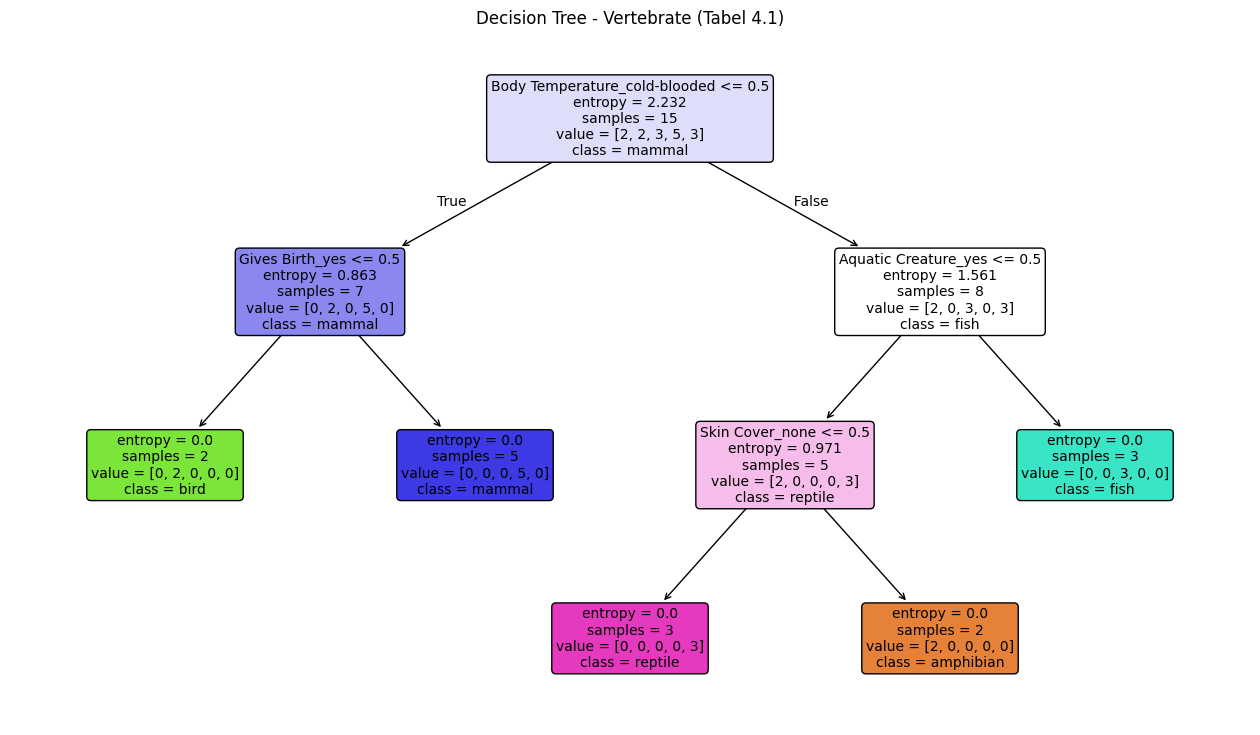

In [15]:
plt.figure(figsize=(16, 9))
plot_tree(dt_vert, feature_names=X_vert.columns, class_names=dt_vert.classes_,
          filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree - Vertebrate (Tabel 4.1)")
plt.show()

### 1.4 Testing
a) Training accuracy.

In [16]:
pred_train_vert = dt_vert.predict(X_vert)
print("Training accuracy:", accuracy_score(y_vert, pred_train_vert))

Training accuracy: 1.0


b) Prediction for a new data point

In [17]:
gila = pd.DataFrame({
    "Body Temperature": ["cold-blooded"], "Skin Cover": ["scales"], "Gives Birth": ["no"],
    "Aquatic Creature": ["no"], "Aerial Creature": ["no"], "Has Legs": ["yes"], "Hibernates": ["yes"]
})
X_gila = pd.get_dummies(gila, dtype=int).reindex(columns=X_vert.columns, fill_value=0)
print("Gila monster prediction:", dt_vert.predict(X_gila)[0])

Gila monster prediction: reptile


c) Leave-One-Out Cross-Validation

In [18]:
scores_vert = cross_val_score(DecisionTreeClassifier(criterion="entropy", random_state=42),
                              X_vert, y_vert, cv=LeaveOneOut())
print("Results for each fold:", scores_vert)
print("LOOCV accuracy:", scores_vert.mean().round(4))

Results for each fold: [1. 0. 1. 1. 1. 1. 1. 0. 1. 1. 1. 1. 1. 1. 1.]
LOOCV accuracy: 0.8667


**Interpretation:** In LOOCV, 2 of the 15 animals were misclassified, resulting in an accuracy of approximately 0.87. The pigeon was misclassified because there are very few examples of the *bird* class. Removing a single observation can substantially change the tree structure. Therefore, results from this small dataset should be interpreted with caution.

### 1.5 Testing with the Training and Test Sets from the Textbook (Tables 4.3 and 4.4)

In [19]:
mammal_train = pd.DataFrame({
    "Name": ["porcupine", "cat", "bat", "whale", "salamander", "komodo dragon", "python", "salmon", "eagle", "guppy"],
    "Body Temperature": ["warm-blooded", "warm-blooded", "warm-blooded", "warm-blooded", "cold-blooded",
                         "cold-blooded", "cold-blooded", "cold-blooded", "warm-blooded", "cold-blooded"],
    "Gives Birth": ["yes", "yes", "yes", "yes", "no", "no", "no", "no", "no", "yes"],
    "Four-legged": ["yes", "yes", "no", "no", "yes", "yes", "no", "no", "no", "no"],
    "Hibernates": ["yes", "no", "yes", "no", "yes", "no", "yes", "no", "no", "no"],
    "Class Label": ["yes", "yes", "no", "no", "no", "no", "no", "no", "no", "no"]   # Bat and whale are treated as noisy examples.
})

mammal_test = pd.DataFrame({
    "Name": ["human", "pigeon", "elephant", "leopard shark", "turtle", "penguin", "eel", "dolphin",
             "spiny anteater", "gila monster"],
    "Body Temperature": ["warm-blooded", "warm-blooded", "warm-blooded", "cold-blooded", "cold-blooded",
                         "cold-blooded", "cold-blooded", "warm-blooded", "warm-blooded", "cold-blooded"],
    "Gives Birth": ["yes", "no", "yes", "yes", "no", "no", "no", "yes", "no", "no"],
    "Four-legged": ["no", "no", "yes", "no", "yes", "no", "no", "no", "yes", "yes"],
    "Hibernates": ["no", "no", "no", "no", "no", "no", "no", "no", "yes", "yes"],
    "Class Label": ["yes", "no", "yes", "no", "no", "no", "no", "yes", "yes", "no"]
})

X_mtrain = pd.get_dummies(mammal_train.drop(columns=["Name", "Class Label"]), dtype=int)
X_mtest = pd.get_dummies(mammal_test.drop(columns=["Name", "Class Label"]), dtype=int)
X_mtest = X_mtest.reindex(columns=X_mtrain.columns, fill_value=0)
y_mtrain = mammal_train["Class Label"]
y_mtest = mammal_test["Class Label"]

dt_mammal = DecisionTreeClassifier(criterion="entropy", random_state=42)
dt_mammal.fit(X_mtrain, y_mtrain)

pred_mtest = dt_mammal.predict(X_mtest)
print("Training accuracy:", accuracy_score(y_mtrain, dt_mammal.predict(X_mtrain)))
print("Test accuracy    :", accuracy_score(y_mtest, pred_mtest))

results = mammal_test[["Name", "Class Label"]].copy()
results["Prediction"] = pred_mtest
results["Correct?"] = results["Class Label"] == results["Prediction"]

Training accuracy: 1.0
Test accuracy    : 0.8


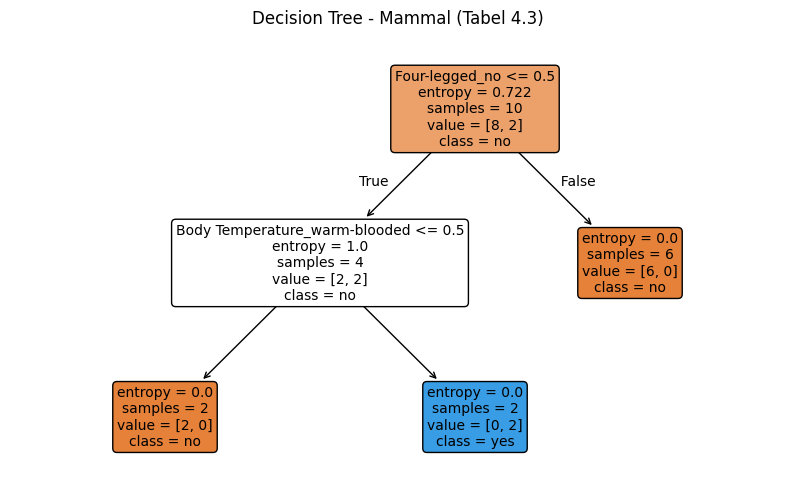

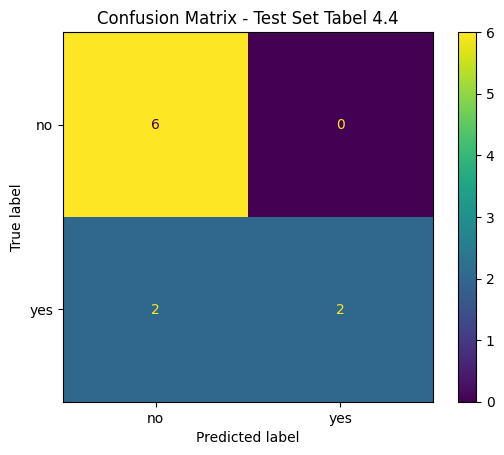

In [20]:
plt.figure(figsize=(10, 6))
plot_tree(dt_mammal, feature_names=X_mtrain.columns, class_names=dt_mammal.classes_,
          filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree - Mammal (Tabel 4.3)")
plt.show()

ConfusionMatrixDisplay.from_predictions(y_mtest, pred_mtest)
plt.title("Confusion Matrix - Test Set Tabel 4.4")
plt.show()

**Interpretation:** The training accuracy is 100%, while the test accuracy is 0.80. This indicates that the tree fits the training data but still makes errors on unseen data. In this dataset, the labels for bat and whale make the mammal-class pattern difficult to learn. The scikit-learn tree structure also differs from Figure 4.25(a) in the textbook because it selects different splits.

---
## 2. Play Tennis Dataset (Sunny)

In [21]:
tennis = pd.DataFrame({
    "Day": ["D" + str(i) for i in range(1, 15)],
    "Outlook": ["Sunny", "Sunny", "Overcast", "Rain", "Rain", "Rain", "Overcast",
                "Sunny", "Sunny", "Rain", "Sunny", "Overcast", "Overcast", "Rain"],
    "Temperature": ["Hot", "Hot", "Hot", "Mild", "Cool", "Cool", "Cool",
                    "Mild", "Cool", "Mild", "Mild", "Mild", "Hot", "Mild"],
    "Humidity": ["High", "High", "High", "High", "Normal", "Normal", "Normal",
                 "High", "Normal", "Normal", "Normal", "High", "Normal", "High"],
    "Wind": ["Weak", "Strong", "Weak", "Weak", "Weak", "Strong", "Strong",
             "Weak", "Weak", "Weak", "Strong", "Strong", "Weak", "Strong"],
    "PlayTennis": ["No", "No", "Yes", "Yes", "Yes", "No", "Yes",
                   "No", "Yes", "Yes", "Yes", "Yes", "Yes", "No"]
})
tennis

,Day,Outlook,Temperature,Humidity,Wind,PlayTennis
0,D1,Sunny,Hot,High,Weak,No
1,D2,Sunny,Hot,High,Strong,No
2,D3,Overcast,Hot,High,Weak,Yes
3,D4,Rain,Mild,High,Weak,Yes
4,D5,Rain,Cool,Normal,Weak,Yes
5,D6,Rain,Cool,Normal,Strong,No
6,D7,Overcast,Cool,Normal,Strong,Yes
7,D8,Sunny,Mild,High,Weak,No
8,D9,Sunny,Cool,Normal,Weak,Yes
9,D10,Rain,Mild,Normal,Weak,Yes


### 2.1 Manual Entropy and Information Gain Calculation
The goal is to compare the results with the calculations in the course material: Gain(Outlook) = 0.24675 is the highest.

In [22]:
def entropy(target_column):
    p = target_column.value_counts() / len(target_column)
    return -(p * np.log2(p)).sum()

def information_gain(data, attribute, target):
    total_entropy = entropy(data[target])
    remaining_entropy = 0
    for value in data[attribute].unique():
        subset = data[data[attribute] == value]
        remaining_entropy += len(subset) / len(data) * entropy(subset[target])
    return total_entropy - remaining_entropy

print("Entropy(S) =", round(entropy(tennis["PlayTennis"]), 5))
for attribute in ["Outlook", "Temperature", "Humidity", "Wind"]:
    print(f"Gain(S, {attribute}) = {information_gain(tennis, attribute, 'PlayTennis'):.5f}")

Entropy(S) = 0.94029
Gain(S, Outlook) = 0.24675
Gain(S, Temperature) = 0.02922
Gain(S, Humidity) = 0.15184
Gain(S, Wind) = 0.04813


In [ ]:
for branch in ["Sunny", "Rain"]:
    subset = tennis[tennis["Outlook"] == branch]
    print(f"Outlook branch = {branch}")
    for attribute in ["Temperature", "Humidity", "Wind"]:
        print(f"   Gain(S_{branch}, {attribute}) = {information_gain(subset, attribute, 'PlayTennis'):.5f}")

Outlook branch = Sunny
   Gain(S_Sunny, Temperature) = 0.57095
   Gain(S_Sunny, Humidity) = 0.97095
   Gain(S_Sunny, Wind) = 0.01997
Outlook branch = Rain
   Gain(S_Rain, Temperature) = 0.01997
   Gain(S_Rain, Humidity) = 0.01997
   Gain(S_Rain, Wind) = 0.97095


The manual calculation identifies **Outlook** as the root because it has the highest information gain, approximately 0.24675. The Sunny branch is then split by **Humidity**, the Rain branch by **Wind**, and the Overcast branch directly predicts **Yes**. There is a small difference between the calculated entropy values and those shown in the course material, possibly due to rounding or a typo.

### 2.2 Decision Tree Induction with scikit-learn

In [24]:
X_tennis = pd.get_dummies(tennis[["Outlook", "Temperature", "Humidity", "Wind"]], dtype=int)
y_tennis = tennis["PlayTennis"]

dt_tennis = DecisionTreeClassifier(criterion="entropy", random_state=42)
dt_tennis.fit(X_tennis, y_tennis)

print(export_text(dt_tennis, feature_names=list(X_tennis.columns)))

|--- Outlook_Overcast <= 0.50
|   |--- Humidity_Normal <= 0.50
|   |   |--- Outlook_Rain <= 0.50
|   |   |   |--- class: No
|   |   |--- Outlook_Rain >  0.50
|   |   |   |--- Wind_Strong <= 0.50
|   |   |   |   |--- class: Yes
|   |   |   |--- Wind_Strong >  0.50
|   |   |   |   |--- class: No
|   |--- Humidity_Normal >  0.50
|   |   |--- Wind_Strong <= 0.50
|   |   |   |--- class: Yes
|   |   |--- Wind_Strong >  0.50
|   |   |   |--- Outlook_Sunny <= 0.50
|   |   |   |   |--- class: No
|   |   |   |--- Outlook_Sunny >  0.50
|   |   |   |   |--- class: Yes
|--- Outlook_Overcast >  0.50
|   |--- class: Yes



### 2.3 Decision Tree Visualization

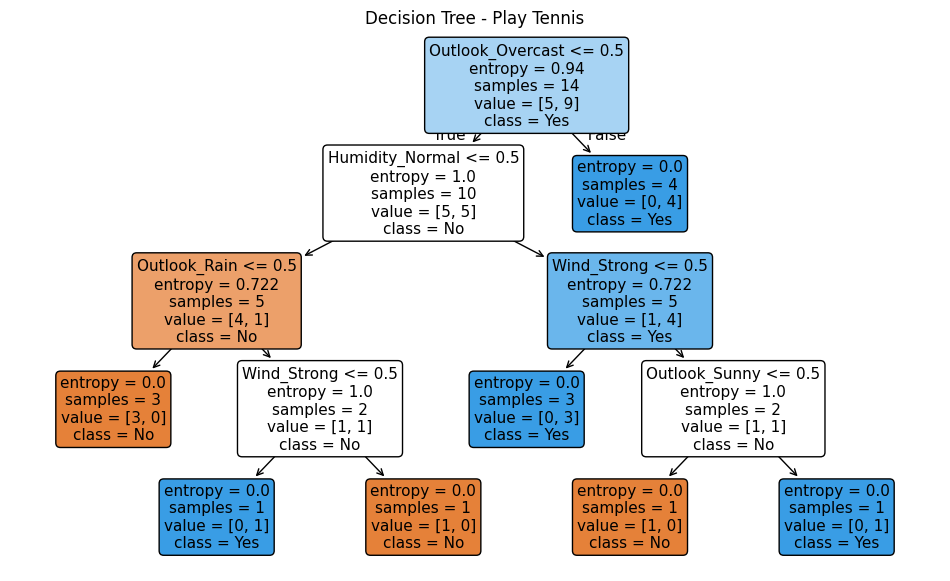

In [25]:
plt.figure(figsize=(12, 7))
plot_tree(dt_tennis, feature_names=X_tennis.columns, class_names=dt_tennis.classes_,
          filled=True, rounded=True, fontsize=11)
plt.title("Decision Tree - Play Tennis")
plt.show()

**Difference from the course material:** The ID3 tree in the course material creates *multiway* branches for Outlook (Sunny, Overcast, and Rain). In this notebook, scikit-learn uses binary splits on one-hot-encoded features, so the tree structure is different. Although the structures differ, their predictions are compared against the rules in the course material for all 36 attribute combinations in the testing section.

### 2.4 Testing
**a) Training accuracy and testing the five rules from the course material.**

In [26]:
print("Training accuracy:", accuracy_score(y_tennis, dt_tennis.predict(X_tennis)))

# One example for each rule in the course material (page 7).
rule_test = pd.DataFrame({
    "Outlook":     ["Sunny", "Sunny", "Overcast", "Rain", "Rain"],
    "Temperature": ["Mild", "Hot", "Cool", "Hot", "Cool"],
    "Humidity":    ["High", "Normal", "High", "Normal", "High"],
    "Wind":        ["Weak", "Strong", "Strong", "Strong", "Weak"],
    "Expected label (course rule)": ["No", "Yes", "Yes", "No", "Yes"]
})
X_rule_test = pd.get_dummies(rule_test.drop(columns=["Expected label (course rule)"]), dtype=int)
X_rule_test = X_rule_test.reindex(columns=X_tennis.columns, fill_value=0)
rule_test["Model prediction"] = dt_tennis.predict(X_rule_test)
rule_test

Training accuracy: 1.0


,Outlook,Temperature,Humidity,Wind,Expected label (course rule),Model prediction
0,Sunny,Mild,High,Weak,No,No
1,Sunny,Hot,Normal,Strong,Yes,Yes
2,Overcast,Cool,High,Strong,Yes,Yes
3,Rain,Hot,Normal,Strong,No,No
4,Rain,Cool,High,Weak,Yes,Yes


**b) Compare the model with the ID3 rules from the course material across all 36 combinations** (3 Outlook × 3 Temperature × 2 Humidity × 2 Wind).

In [27]:
def course_rule(row):
    if row["Outlook"] == "Overcast":
        return "Yes"
    if row["Outlook"] == "Sunny":
        return "No" if row["Humidity"] == "High" else "Yes"
    return "No" if row["Wind"] == "Strong" else "Yes"     # Outlook = Rain

all_combinations = pd.DataFrame([(o, t, h, w) for o in ["Sunny", "Overcast", "Rain"]
                                   for t in ["Hot", "Mild", "Cool"]
                                   for h in ["High", "Normal"]
                                   for w in ["Weak", "Strong"]],
                     columns=["Outlook", "Temperature", "Humidity", "Wind"])
X_all_combinations = pd.get_dummies(all_combinations, dtype=int).reindex(columns=X_tennis.columns, fill_value=0)

matches_rules = (dt_tennis.predict(X_all_combinations) == all_combinations.apply(course_rule, axis=1))
print(f"Predictions matching the course rules: {matches_rules.sum()} out of {len(all_combinations)} combinations")

Predictions matching the course rules: 36 out of 36 combinations


**c) Leave-One-Out Cross-Validation** (the dataset contains only 14 rows).

In [28]:
scores_tennis = cross_val_score(DecisionTreeClassifier(criterion="entropy", random_state=42),
                                X_tennis, y_tennis, cv=LeaveOneOut())
print("Results for each fold:", scores_tennis)
print("LOOCV accuracy:", scores_tennis.mean().round(4))

Results for each fold: [1. 1. 1. 0. 1. 0. 1. 0. 1. 1. 0. 0. 1. 0.]
LOOCV accuracy: 0.5714


**Interpretation:** The tree correctly predicts all training observations, and its results match the five rules in the course material. However, LOOCV accuracy is lower. Since the dataset contains only 14 rows, removing one row can affect the resulting tree. Therefore, 100% training accuracy alone is not enough to assess the model’s ability to predict new data.

 

## 3. Predict Students' Dropout and Academic Success Dataset

In [29]:
df = pd.read_csv("dataset.csv", sep=None, engine="python", encoding="utf-8-sig")
df.columns = df.columns.str.strip()   # buang spasi di awal/akhir name columns

print("Dataset shape:", df.shape)       # Expected shape: (4424, 35).
df.head()

Dataset shape: (4424, 35)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [30]:
print(df.shape)
print(df.columns.tolist())

(4424, 35)
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 'Target']


Total missing values: 0

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


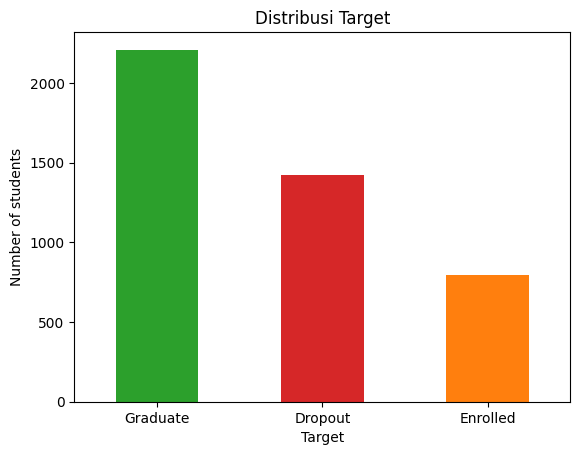

In [31]:
print("Total missing values:", df.isnull().sum().sum())
print()
print(df["Target"].value_counts())

df["Target"].value_counts().plot(kind="bar", color=["tab:green", "tab:red", "tab:orange"])
plt.title("Distribusi Target")
plt.ylabel("Number of students")
plt.xticks(rotation=0)
plt.show()

No missing values were found. **Enrolled** is the smallest class (approximately 18% of the data), so it may be more difficult to predict. Columns such as `Course` and `Marital status` are already represented by numeric codes and are used directly. Keep in mind that the model may treat these codes as ordered numerical values, even though they represent categories.

### 3.1 Training and Testing Split (80:20)

In [32]:
X = df.drop(columns=["Target"])
y = df["Target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (3539, 34)
Test set: (885, 34)


`stratify=y` preserves the proportions of Dropout, Enrolled, and Graduate in both the training and test sets.

### 3.2 Decision Tree Induction (without a depth limit)

In [33]:
dt_full = DecisionTreeClassifier(criterion="entropy", random_state=42)
dt_full.fit(X_train, y_train)

print("Tree depth :", dt_full.get_depth())
print("Number of leaves:", dt_full.get_n_leaves())
print("Training accuracy:", round(accuracy_score(y_train, dt_full.predict(X_train)), 4))
print("Test accuracy    :", round(accuracy_score(y_test, dt_full.predict(X_test)), 4))

Tree depth : 24
Number of leaves: 636
Training accuracy: 1.0
Test accuracy    : 0.6576


### 3.3 Testing

              precision    recall  f1-score   support

     Dropout       0.67      0.67      0.67       284
    Enrolled       0.31      0.35      0.33       159
    Graduate       0.79      0.76      0.77       442

    accuracy                           0.66       885
   macro avg       0.59      0.59      0.59       885
weighted avg       0.67      0.66      0.66       885



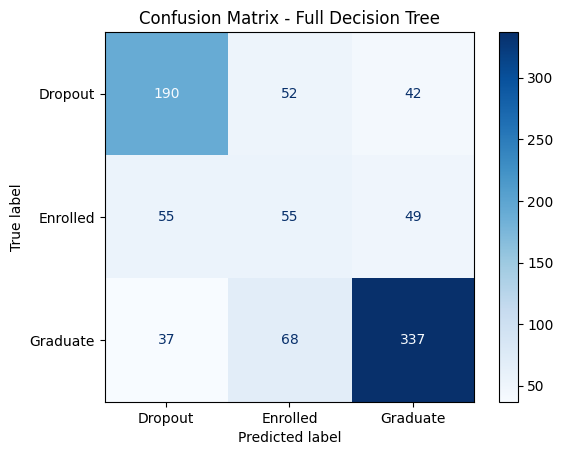

In [34]:
pred_full = dt_full.predict(X_test)
print(classification_report(y_test, pred_full))

ConfusionMatrixDisplay.from_predictions(y_test, pred_full, cmap="Blues")
plt.title("Confusion Matrix - Full Decision Tree")
plt.show()

**Interpretation:** Training accuracy reaches 100%, while test accuracy is approximately 0.66. This difference indicates **overfitting**. The tree has a depth of 24 and 636 leaves, making it highly complex. In the classification report, the Enrolled class has the lowest recall and is often misclassified as another class.

### 3.4 Full Tree Visualization

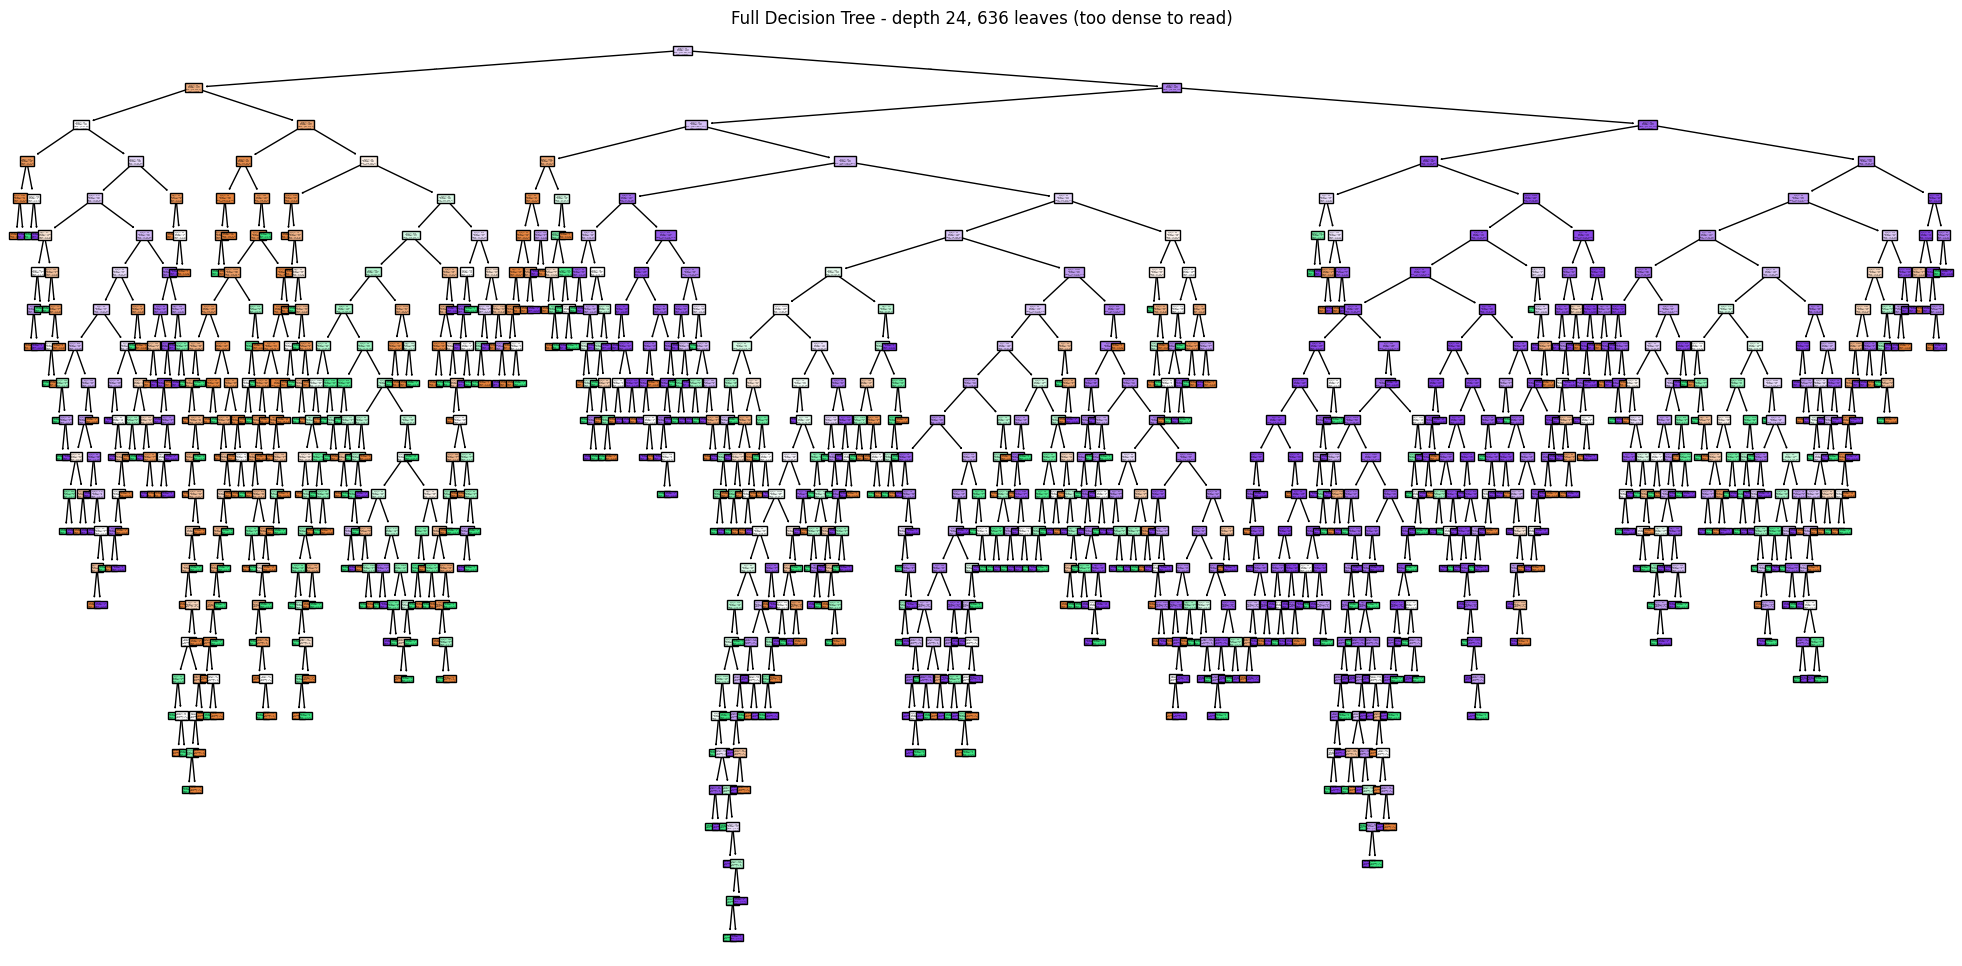

In [35]:
plt.figure(figsize=(25, 12))
plot_tree(dt_full, filled=True, class_names=dt_full.classes_)
plt.title(f"Full Decision Tree - depth {dt_full.get_depth()}, {dt_full.get_n_leaves()} leaves (too dense to read)")
plt.show()

The full tree is difficult to read because it contains many nodes. To make its initial structure easier to inspect, the following visualization displays only part of the tree's depth. This truncation applies to the image, not to the trained model itself.

### 3.5 Tree Visualization with Display Depth Limited to 3

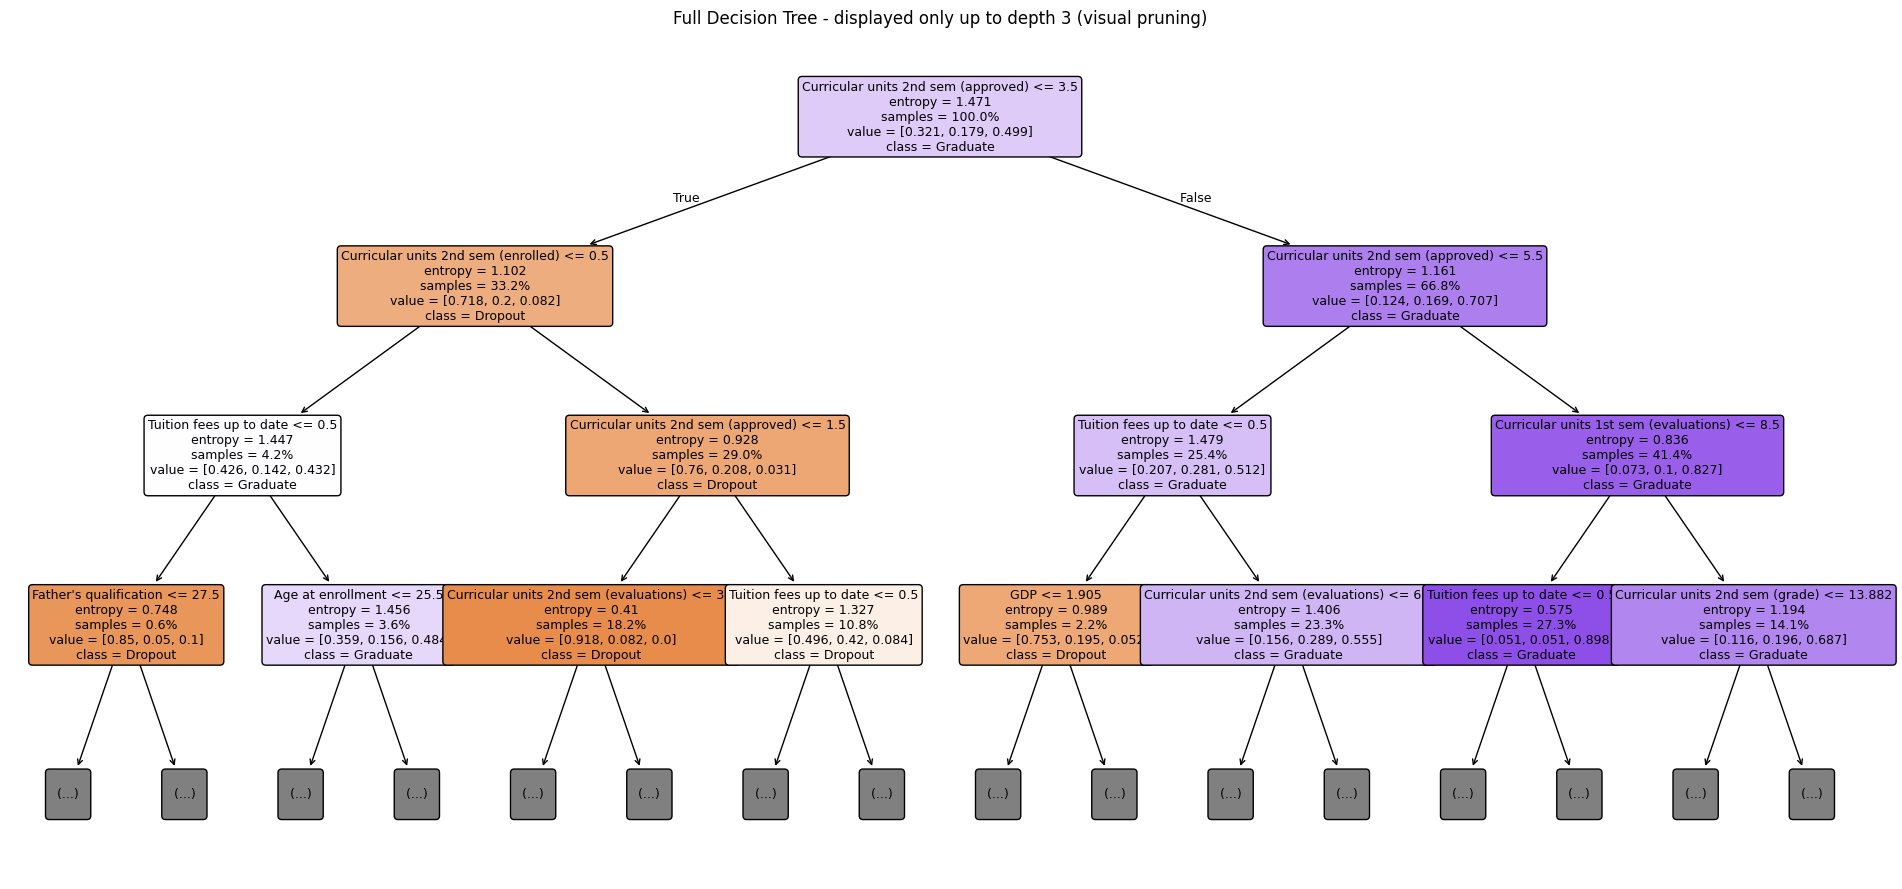

In [36]:
plt.figure(figsize=(24, 11))
plot_tree(dt_full, max_depth=3, feature_names=X.columns, class_names=dt_full.classes_,
          filled=True, rounded=True, fontsize=9, proportion=True)
plt.title("Full Decision Tree - displayed only up to depth 3 (visual pruning)")
plt.show()

**Visualization notes:**
- The model remains `dt_full`. The `max_depth=3` parameter in `plot_tree` limits only what is displayed; it does not prune the original model.
- The figure shows levels 0 through 3. Branches below these levels are abbreviated with `...`.
- The root split is `Curricular units 2nd sem (approved) <= 3.5`, which represents the number of second-semester courses passed. In the training data, the left branch contains more Dropout students, while the right branch contains more Graduate students.
- Features visible at the next levels include the number of second-semester courses, tuition-fee payment status, and first-semester evaluation.
- The original tree still contains deeper branches. This limited visualization helps show the initial pattern but does not represent every rule used by the model.

### 3.6 Comparison: Pre-pruning with `max_depth`

In [37]:
depth_results = []
for d in [2, 3, 4, 5, 6, 8, 10, None]:
    model = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=42)
    model.fit(X_train, y_train)
    depth_results.append({
        "max_depth": "full" if d is None else d,
        "number of leaves": model.get_n_leaves(),
        "training accuracy": round(accuracy_score(y_train, model.predict(X_train)), 4),
        "test accuracy": round(accuracy_score(y_test, model.predict(X_test)), 4)
    })
pd.DataFrame(depth_results)

,max_depth,number of leaves,training accuracy,test accuracy
0,2,4,0.7109,0.7153
1,3,8,0.7304,0.7333
2,4,16,0.7429,0.7288
3,5,32,0.7561,0.7345
4,6,55,0.7737,0.7401
5,8,137,0.8160,0.7277
6,10,253,0.8647,0.7119
7,full,636,1.0000,0.6576


Test accuracy (max_depth=4): 0.7288
              precision    recall  f1-score   support

     Dropout       0.89      0.61      0.72       284
    Enrolled       0.44      0.26      0.33       159
    Graduate       0.72      0.98      0.83       442

    accuracy                           0.73       885
   macro avg       0.68      0.61      0.63       885
weighted avg       0.72      0.73      0.71       885



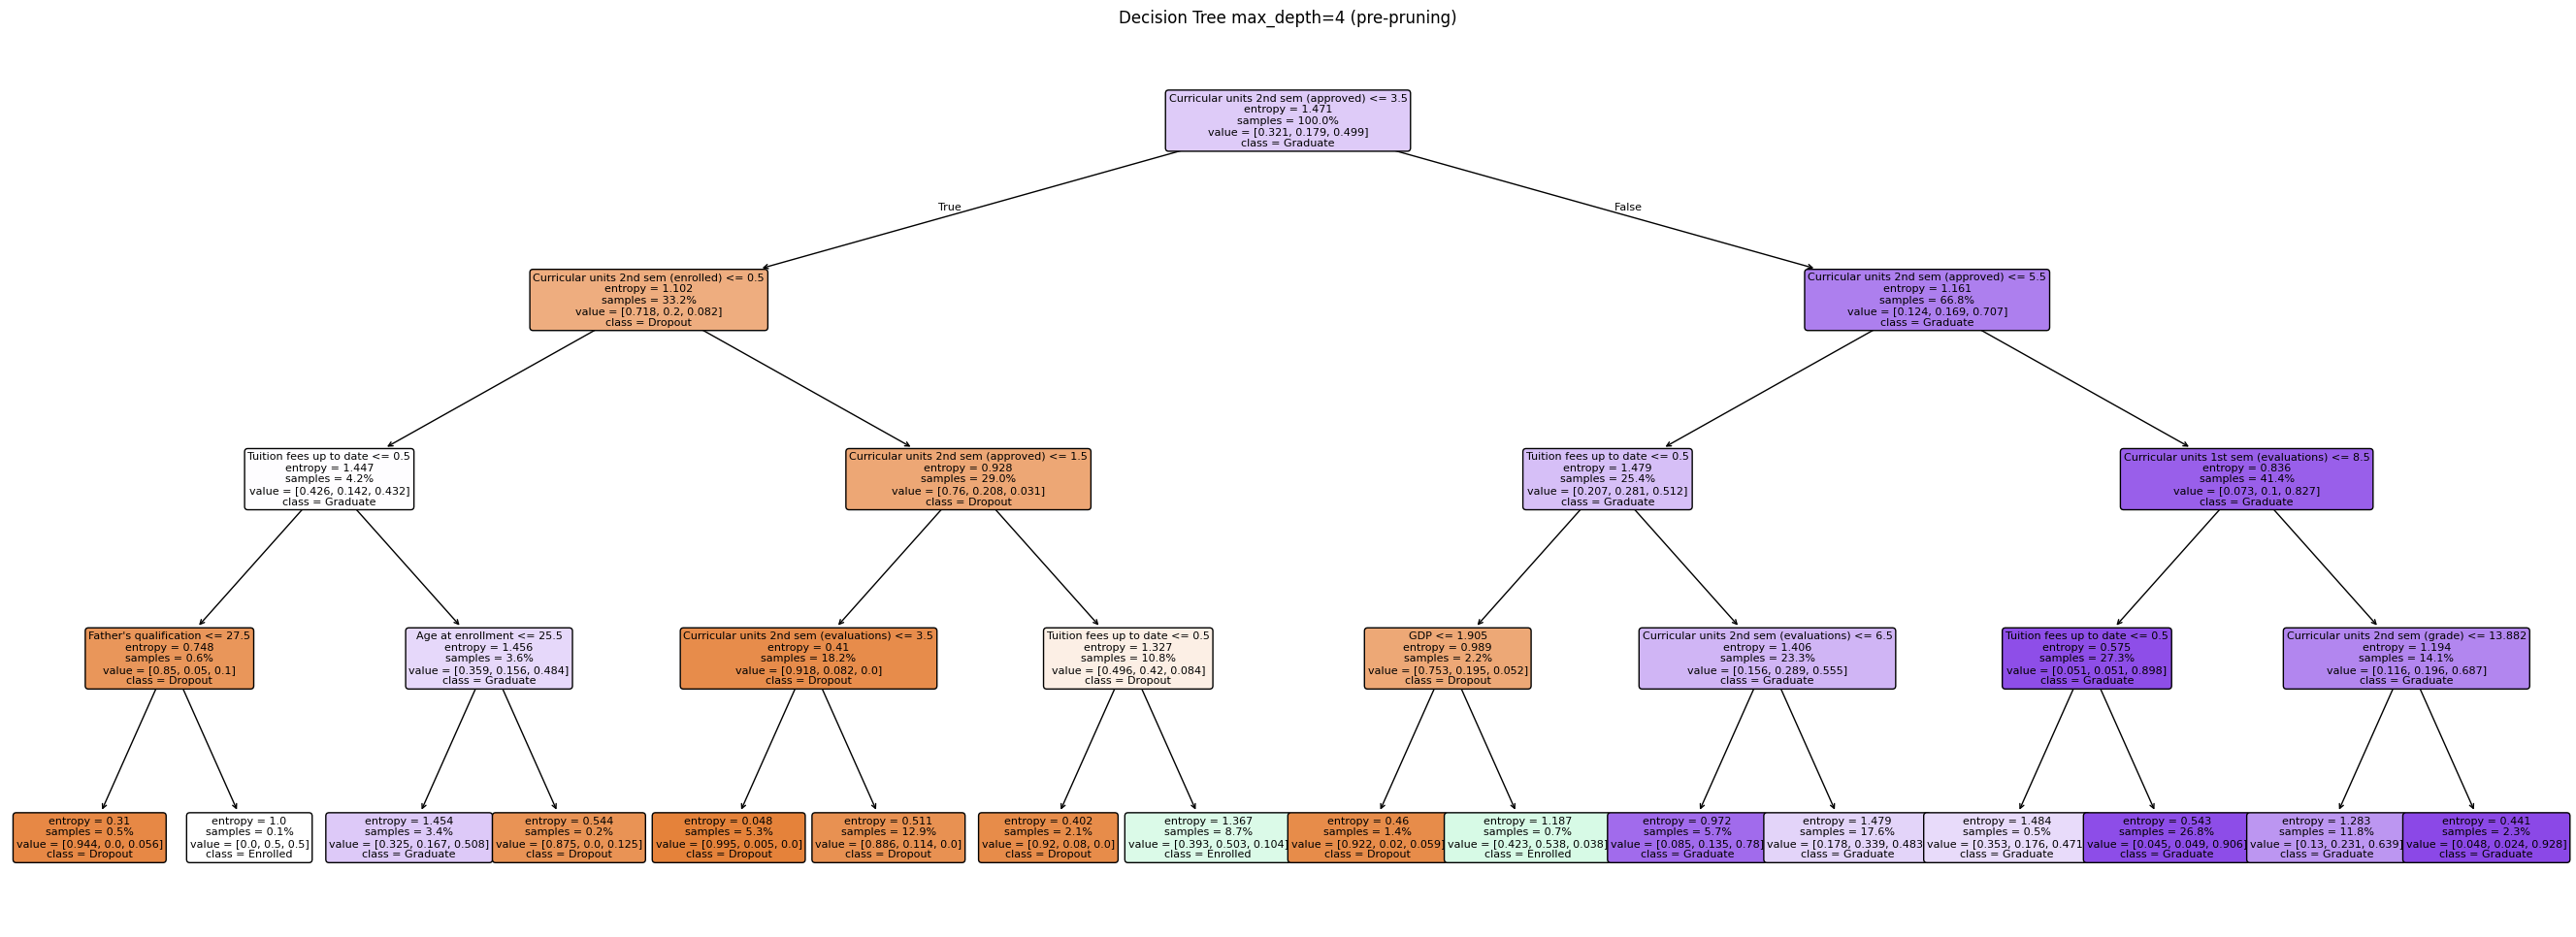

In [38]:
dt_prune = DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=42)
dt_prune.fit(X_train, y_train)
pred_prune = dt_prune.predict(X_test)

print("Test accuracy (max_depth=4):", round(accuracy_score(y_test, pred_prune), 4))
print(classification_report(y_test, pred_prune))

plt.figure(figsize=(34, 12))
plot_tree(dt_prune, feature_names=X.columns, class_names=dt_prune.classes_,
          filled=True, rounded=True, fontsize=8, proportion=True)
plt.title("Decision Tree max_depth=4 (pre-pruning)")
plt.show()

### 3.7 Feature Importance and Feature Selection

#### a) Decision Tree Feature Importance

Feature: 0, Marital status, Score: 0.00000
Feature: 1, Application mode, Score: 0.00000
Feature: 2, Application order, Score: 0.00000
Feature: 3, Course, Score: 0.00000
Feature: 4, Daytime/evening attendance, Score: 0.00000
Feature: 5, Previous qualification, Score: 0.00000
Feature: 6, Nacionality, Score: 0.00000
Feature: 7, Mother's qualification, Score: 0.00000
Feature: 8, Father's qualification, Score: 0.00361
Feature: 9, Mother's occupation, Score: 0.00000
Feature: 10, Father's occupation, Score: 0.00000
Feature: 11, Displaced, Score: 0.00000
Feature: 12, Educational special needs, Score: 0.00000
Feature: 13, Debtor, Score: 0.00000
Feature: 14, Tuition fees up to date, Score: 0.08915
Feature: 15, Gender, Score: 0.00000
Feature: 16, Scholarship holder, Score: 0.00000
Feature: 17, Age at enrollment, Score: 0.00366
Feature: 18, International, Score: 0.00000
Feature: 19, Curricular units 1st sem (credited), Score: 0.00000
Feature: 20, Curricular units 1st sem (enrolled), Score: 0.00000

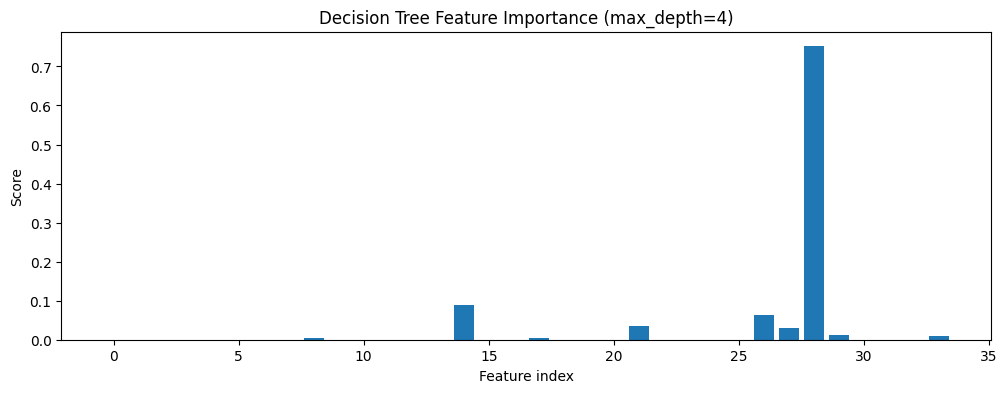

In [39]:
importance = dt_prune.feature_importances_

for i, v in enumerate(importance):
    print(f"Feature: {i}, {X.columns[i]}, Score: {v:.5f}")

plt.figure(figsize=(12, 4))
plt.bar([x for x in range(len(importance))], importance)
plt.title("Decision Tree Feature Importance (max_depth=4)")
plt.xlabel("Feature index")
plt.ylabel("Score")
plt.show()

In [40]:
importance_comparison = pd.DataFrame({
    "full tree": dt_full.feature_importances_,
    "max_depth=4": dt_prune.feature_importances_
}, index=X.columns)

print("Number of features with importance > 0")
print("  full tree :", (importance_comparison["full tree"] > 0).sum(), "out of", X.shape[1])
print("  max_depth=4:", (importance_comparison["max_depth=4"] > 0).sum(), "out of", X.shape[1])
importance_comparison.sort_values("max_depth=4", ascending=False).head(10).round(4)

Number of features with importance > 0
  full tree : 33 out of 34
  max_depth=4: 9 out of 34


,full tree,max_depth=4
Curricular units 2nd sem (approved),0.3181,0.7513
Tuition fees up to date,0.0379,0.0891
Curricular units 2nd sem (enrolled),0.0389,0.0627
Curricular units 1st sem (evaluations),0.0350,0.0356
Curricular units 2nd sem (evaluations),0.0407,0.0308
Curricular units 2nd sem (grade),0.0517,0.0124
GDP,0.0305,0.0107
Age at enrollment,0.0405,0.0037
Father's qualification,0.0285,0.0036
Marital status,0.0035,0.0000


**Interpretation:** `Curricular units 2nd sem (approved)` has the highest feature importance in the tree with `max_depth=4`. In the full tree, importance is distributed across more features because the structure is more complex. Feature importance shows how the model uses features when creating splits, but it does not prove that a feature causes a particular academic outcome.

Feature: 0, Marital status, Score: 0.00000
Feature: 1, Application mode, Score: 0.00000
Feature: 2, Application order, Score: 0.00000
Feature: 3, Course, Score: 0.00000
Feature: 4, Daytime/evening attendance, Score: 0.00000
Feature: 5, Previous qualification, Score: 0.00000
Feature: 6, Nacionality, Score: 0.00000
Feature: 7, Mother's qualification, Score: 0.00000
Feature: 8, Father's qualification, Score: -0.00158
Feature: 9, Mother's occupation, Score: 0.00000
Feature: 10, Father's occupation, Score: 0.00000
Feature: 11, Displaced, Score: 0.00000
Feature: 12, Educational special needs, Score: 0.00000
Feature: 13, Debtor, Score: 0.00000
Feature: 14, Tuition fees up to date, Score: 0.03706
Feature: 15, Gender, Score: 0.00000
Feature: 16, Scholarship holder, Score: 0.00000
Feature: 17, Age at enrollment, Score: 0.00203
Feature: 18, International, Score: 0.00000
Feature: 19, Curricular units 1st sem (credited), Score: 0.00000
Feature: 20, Curricular units 1st sem (enrolled), Score: 0.0000

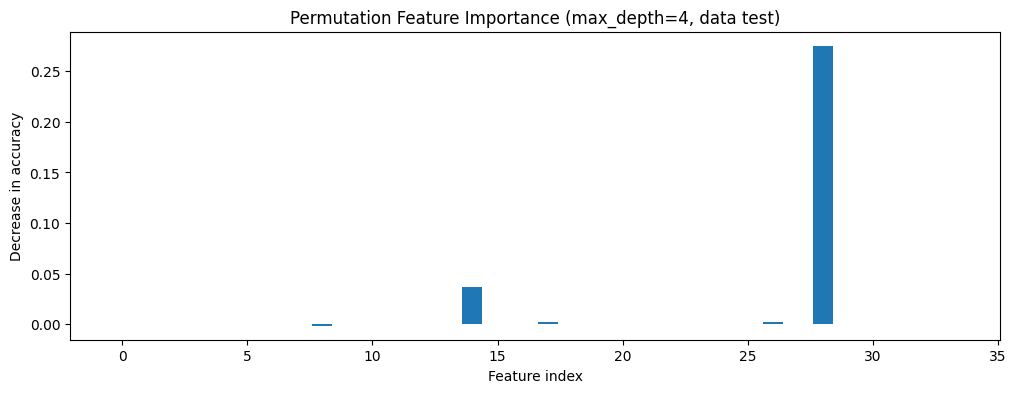

In [41]:
results = permutation_importance(dt_prune, X_test, y_test, scoring="accuracy", n_repeats=10, random_state=42)

for i, v in enumerate(results.importances_mean):
    print(f"Feature: {i}, {X.columns[i]}, Score: {v:.5f}")

plt.figure(figsize=(12, 4))
plt.bar([x for x in range(len(results.importances_mean))], results.importances_mean)
plt.title("Permutation Feature Importance (max_depth=4, data test)")
plt.xlabel("Feature index")
plt.ylabel("Decrease in accuracy")
plt.show()

In [42]:
perm = pd.Series(results.importances_mean, index=X.columns).sort_values(ascending=False)
print("Features with permutation importance > 0:")
perm[perm > 0].round(4)

Features with permutation importance > 0:


Curricular units 2nd sem (approved)    0.2753
Tuition fees up to date                0.0371
Curricular units 2nd sem (enrolled)    0.0023
Age at enrollment                      0.0020
dtype: float64

**Interpretation:** Permutation importance measures the change in accuracy when a feature's values are shuffled. A positive value means that shuffling the feature reduces accuracy; a value close to zero means its impact is small in this evaluation. A negative value means accuracy increases slightly after shuffling. These results depend on the model and evaluation data, so they do not mean that a feature is always useless.

In [43]:
selected_features = list(perm[perm > 0].index)
print("Number of selected features:", len(selected_features))

feature_selection_results = []
for d in [4, None]:
    for name, columns in [("all features", list(X.columns)), ("selected features", selected_features)]:
        model = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=42)
        model.fit(X_train[columns], y_train)
        feature_selection_results.append({
            "max_depth": "full" if d is None else d,
            "features": f"{name} ({len(columns)})",
            "training accuracy": round(accuracy_score(y_train, model.predict(X_train[columns])), 4),
            "test accuracy": round(accuracy_score(y_test, model.predict(X_test[columns])), 4)
        })
pd.DataFrame(feature_selection_results)

Number of selected features: 4


,max_depth,features,training accuracy,test accuracy
0,4,all features (34),0.7429,0.7288
1,4,selected features (4),0.7463,0.7379
2,full,all features (34),1.0000,0.6576
3,full,selected features (4),0.8192,0.6893


In this experiment, the four features with positive permutation importance were used to retrain the models. Their test accuracy was higher than that of the models using all features. However, the features were selected using permutation importance calculated on the same test set, so this comparison is exploratory and may be overly optimistic. For a more reliable evaluation, feature selection should be performed using only training/validation data, and the test set should be used once for the final evaluation.

## Conclusion
1. **Vertebrate:** The tree predicts the training data well, but the LOOCV and test-set results show that a small dataset and difficult class labels can make predictions on new data less stable.
2. **Play Tennis:** Entropy and information gain are used to select Outlook as the root, after which the Sunny and Rain branches are split further. The scikit-learn tree differs from the ID3 tree in the course material, so its predictions are compared across all 36 attribute combinations.
3. **Student Dropout:** The full tree achieves 100% training accuracy but approximately 0.66 test accuracy and has a complex structure, indicating overfitting. A tree with a smaller depth limit achieves better test results in this experiment. `Curricular units 2nd sem (approved)` is the most dominant feature according to feature importance. Feature selection improves accuracy in this experiment, but the result should be re-evaluated using a feature-selection process that does not use the test set.